# import basic libraries

In [4]:
import shap
shap.initjs()

In [5]:
# basic libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ML libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib


# Advanced ML models
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import VotingClassifier

# Evaluation
from sklearn.metrics import roc_auc_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve, auc
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Imbalance handling
from imblearn.over_sampling import SMOTE

# load dataset

In [6]:
df = pd.read_csv('CardioShieldDataSet.csv')

# basic eda

In [7]:
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [8]:
df.tail()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
69995,99993,19240,2,168,76.0,120,80,1,1,1,0,1,0
69996,99995,22601,1,158,126.0,140,90,2,2,0,0,1,1
69997,99996,19066,2,183,105.0,180,90,3,1,0,1,0,1
69998,99998,22431,1,163,72.0,135,80,1,2,0,0,0,1
69999,99999,20540,1,170,72.0,120,80,2,1,0,0,1,0


In [9]:
df.shape

(70000, 13)

In [10]:
df.describe()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [12]:
df.isnull().sum()

,0
id,0
age,0
gender,0
height,0
weight,0
ap_hi,0
ap_lo,0
cholesterol,0
gluc,0
smoke,0


In [13]:
df.duplicated().sum()

np.int64(0)

# Data Cleaning

In [14]:
df = df.drop(columns=['id'])

In [15]:
df['age'] = df['age'] / 365

## Univariate Analysis

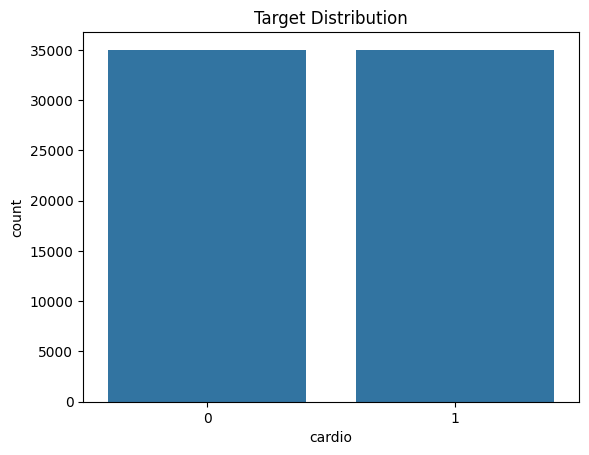

In [16]:
sns.countplot(x='cardio', data=df)
plt.title("Target Distribution")
plt.show()

### Distribution of Important Features

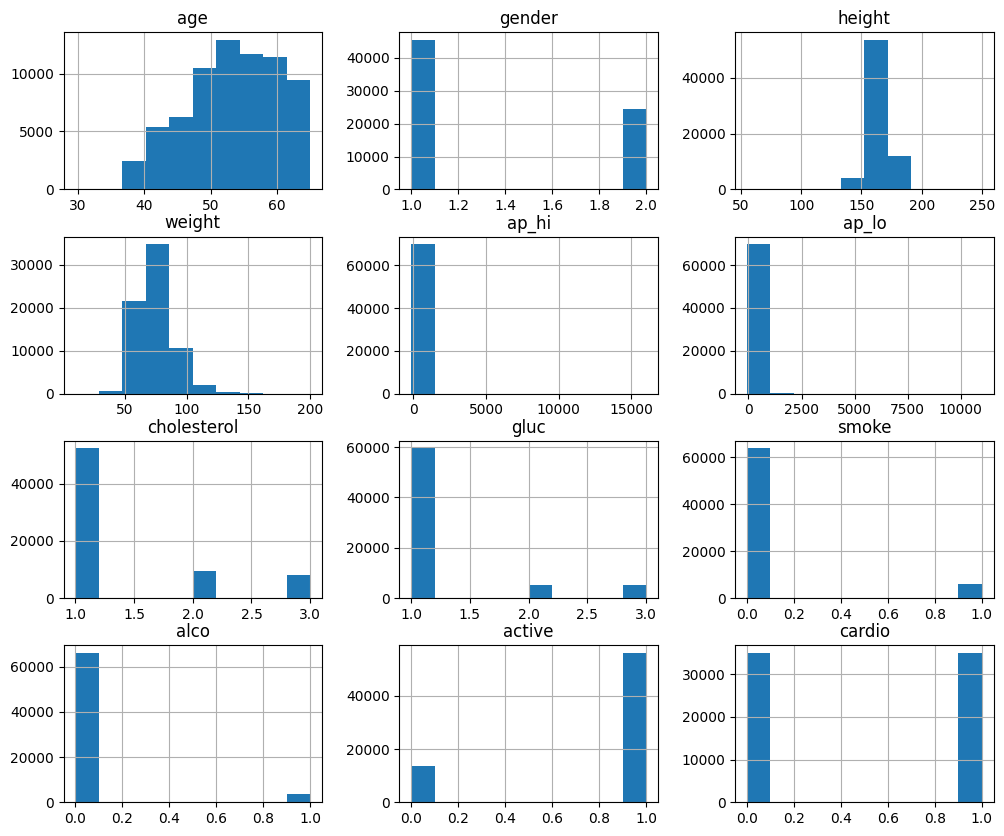

In [17]:
df.hist(figsize=(12,10))
plt.show()

### Bivariate Analysis

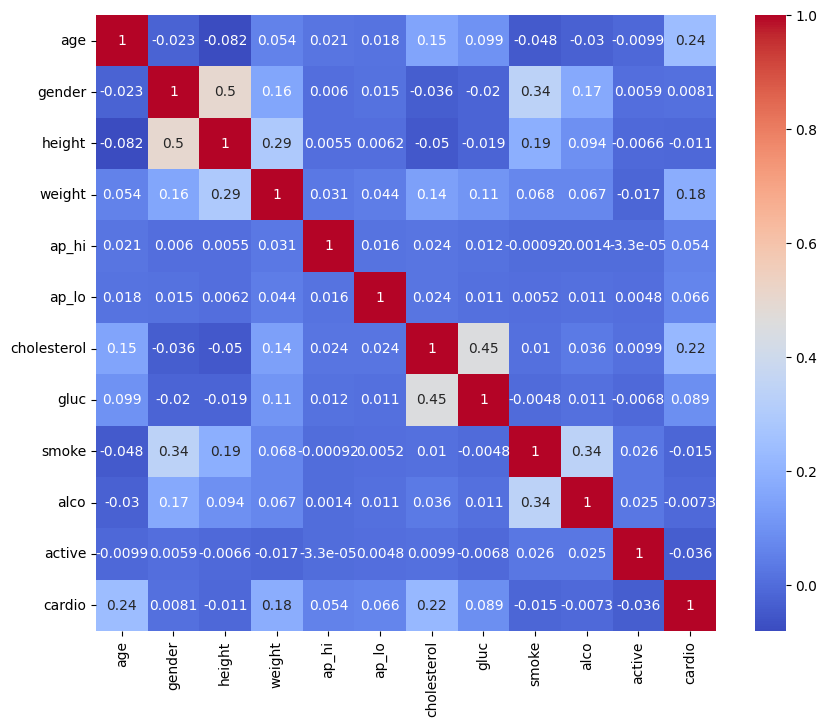

In [18]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.show()

### Outlier Detection

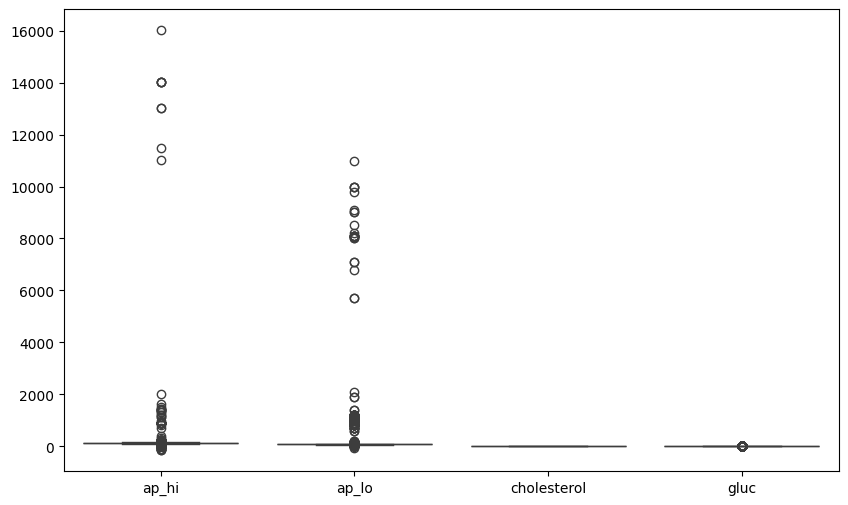

In [19]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df[['ap_hi', 'ap_lo', 'cholesterol', 'gluc']])
plt.show()

### Outlier Removal

In [20]:
df = df[(df['ap_hi'] > 50) & (df['ap_hi'] < 250)]
df = df[(df['ap_lo'] > 30) & (df['ap_lo'] < 200)]

# Feature Engineering

### Create BMI Feature

In [21]:
df['bmi'] = df['weight'] / ((df['height']/100)**2)

## Pulse Pressure

In [22]:
df['pulse_pressure'] = df['ap_hi'] - df['ap_lo']

## Age × BP interaction

In [23]:
df['age_bp_interaction'] = df['age'] * df['ap_hi']

## Glucose × BMI interaction

In [24]:
df['glucose_bmi'] = df['gluc'] * df['bmi']

### Define Features & Target

In [25]:
X = df.drop('cardio', axis=1)
y = df['cardio']

## Train Test Split

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,stratify=y
)

In [27]:
# Split training into train + calibration FIRST
X_train_base, X_cal, y_train_base, y_cal = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42
)


## Handle Class Imbalance

In [28]:
# Apply SMOTE ONLY on training base
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_base, y_train_base)

In [29]:
# Tree datasets
X_train_tree = X_train_res
X_test_tree = X_test

## Feature Scaling

In [30]:
#scaling only for mlp
scaler = StandardScaler()
X_train_mlp = scaler.fit_transform(X_train_res)
X_test_mlp = scaler.transform(X_test)

## Define Cross Validation Strategy

In [31]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# models training

## XGBoost + GridSearch

In [32]:
xgb = XGBClassifier(
    use_label_encoder=False,
    eval_metric='logloss'
)

param_xgb = {
    'n_estimators': [200, 300],
    'max_depth': [4, 6],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.8, 1.0]
}

grid_xgb = GridSearchCV(
    xgb,
    param_xgb,
    cv=cv,
    scoring='recall',   # prioritizing recall
    n_jobs=-1
)

grid_xgb.fit(X_train_res, y_train_res)

best_xgb = grid_xgb.best_estimator_
print("Best XGBoost Params:", grid_xgb.best_params_)

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [14:47:37] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best XGBoost Params: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 200, 'subsample': 1.0}


## LightGBM + GridSearch

In [33]:
lgb = LGBMClassifier(class_weight='balanced')

param_lgb = {
    'n_estimators': [200, 300],
    'max_depth': [-1, 6],
    'learning_rate': [0.05, 0.1],
    'num_leaves': [31, 50]
}

grid_lgb = GridSearchCV(
    lgb,
    param_lgb,
    cv=cv,
    scoring='recall',
    n_jobs=-1
)

grid_lgb.fit(X_train_res, y_train_res)

best_lgb = grid_lgb.best_estimator_
print("Best LightGBM Params:", grid_lgb.best_params_)

[LightGBM] [Info] Number of positive: 22232, number of negative: 22232
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006344 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1515
[LightGBM] [Info] Number of data points in the train set: 44464, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with pos

## Neural Network (MLP)

In [34]:
mlp = MLPClassifier(max_iter=500)

param_mlp = {
    'hidden_layer_sizes': [(64,), (128,)],
    'alpha': [0.0001, 0.001],
    'learning_rate_init': [0.001, 0.01]
}

grid_mlp = GridSearchCV(
    mlp,
    param_mlp,
    cv=cv,
    scoring='recall',
    n_jobs=-1
)

grid_mlp.fit(X_train_mlp, y_train_res)

best_mlp = grid_mlp.best_estimator_
print("Best MLP Params:", grid_mlp.best_params_)

Best MLP Params: {'alpha': 0.001, 'hidden_layer_sizes': (128,), 'learning_rate_init': 0.001}


## TabNet

In [35]:
!pip install pytorch_tabnet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 3.6 MB/s eta 0:00:00


# Convert to numpy

In [36]:
X_train_np = X_train_base.values
y_train_np = y_train_base.values

X_val_np = X_cal.values
y_val_np = y_cal.values

In [37]:
from pytorch_tabnet.tab_model import TabNetClassifier
import torch

tabnet = TabNetClassifier(
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-3),
    scheduler_params={"step_size":10, "gamma":0.9},
    scheduler_fn=torch.optim.lr_scheduler.StepLR,
    mask_type='sparsemax'
)

/usr/local/lib/python3.12/dist-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cuda
  warnings.warn(f"Device used : {self.device}")


## Fit With Validation + Early Stopping

In [38]:
tabnet.fit(
    X_train_np, y_train_np,
    eval_set=[(X_val_np, y_val_np)],
    eval_metric=['auc'],
    max_epochs=100,
    patience=20,
    batch_size=1024,
    virtual_batch_size=128
)

epoch 0  | loss: 0.69236 | val_0_auc: 0.52085 |  0:00:07s
epoch 1  | loss: 0.6198  | val_0_auc: 0.54875 |  0:00:12s
epoch 2  | loss: 0.60223 | val_0_auc: 0.61618 |  0:00:17s
epoch 3  | loss: 0.59132 | val_0_auc: 0.70344 |  0:00:19s
epoch 4  | loss: 0.58161 | val_0_auc: 0.74393 |  0:00:21s
epoch 5  | loss: 0.5773  | val_0_auc: 0.75068 |  0:00:24s
epoch 6  | loss: 0.57462 | val_0_auc: 0.77204 |  0:00:26s
epoch 7  | loss: 0.56994 | val_0_auc: 0.78047 |  0:00:27s
epoch 8  | loss: 0.56883 | val_0_auc: 0.78405 |  0:00:29s
epoch 9  | loss: 0.56712 | val_0_auc: 0.78469 |  0:00:31s
epoch 10 | loss: 0.56518 | val_0_auc: 0.78603 |  0:00:33s
epoch 11 | loss: 0.56375 | val_0_auc: 0.78692 |  0:00:35s
epoch 12 | loss: 0.56317 | val_0_auc: 0.78816 |  0:00:37s
epoch 13 | loss: 0.56158 | val_0_auc: 0.78907 |  0:00:39s
epoch 14 | loss: 0.56166 | val_0_auc: 0.78937 |  0:00:41s
epoch 15 | loss: 0.56033 | val_0_auc: 0.78921 |  0:00:43s
epoch 16 | loss: 0.5586  | val_0_auc: 0.7901  |  0:00:45s
epoch 17 | los

/usr/local/lib/python3.12/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


### Evaluating

In [39]:
y_prob_tab = tabnet.predict_proba(X_test.values)[:,1]
y_pred_tab = tabnet.predict(X_test.values)

print("TabNet ROC-AUC:", roc_auc_score(y_test, y_prob_tab))
print("TabNet Recall:", recall_score(y_test, y_pred_tab))
print("TabNet Precision:", precision_score(y_test, y_pred_tab))

TabNet ROC-AUC: 0.7870728441775582
TabNet Recall: 0.6851770236521229
TabNet Precision: 0.7370417193426043


## Evaluate All Models

In [40]:
models = {
    "XGBoost": best_xgb,
    "LightGBM": best_lgb,
    "MLP": best_mlp,
    "TabNet": tabnet
}

for name, model in models.items():

    if name == "MLP":
        X_eval = X_test_mlp
    elif name == "TabNet":
        X_eval = X_test.values # Convert DataFrame to NumPy array
    else:
        X_eval = X_test

    y_pred = model.predict(X_eval)
    y_prob = model.predict_proba(X_eval)[:,1]

    roc = roc_auc_score(y_test, y_prob)
    recall = recall_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)

    precision_vals, recall_vals, _ = precision_recall_curve(y_test, y_prob)
    pr_auc = auc(recall_vals, precision_vals)

    print(f"\n{name}")
    print("ROC-AUC:", roc)
    print("Recall:", recall)
    print("Precision:", precision)
    print("PR-AUC:", pr_auc)


XGBoost
ROC-AUC: 0.7978224395473554
Recall: 0.7022183046863523
Precision: 0.739938080495356
PR-AUC: 0.7812810151727566

LightGBM
ROC-AUC: 0.7966478025304813
Recall: 0.6992801527838989
Precision: 0.7407407407407407
PR-AUC: 0.7791028764082216

MLP
ROC-AUC: 0.794665628333595
Recall: 0.6998677831643896
Precision: 0.7355257063455304
PR-AUC: 0.7822551490077746

TabNet
ROC-AUC: 0.7870728441775582
Recall: 0.6851770236521229
Precision: 0.7370417193426043
PR-AUC: 0.772693403800458


## Build Ensemble Model

In [41]:
ensemble = VotingClassifier(
    estimators=[
        ('xgb', best_xgb),
        ('lgb', best_lgb),
        ('mlp', best_mlp)
    ],
    voting='soft'
)

ensemble.fit(X_train_res, y_train_res)

y_prob_ens = ensemble.predict_proba(X_test)[:,1]
print("Ensemble ROC-AUC:", roc_auc_score(y_test, y_prob_ens))

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [14:58:27] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[LightGBM] [Info] Number of positive: 22232, number of negative: 22232
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003952 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1515
[LightGBM] [Info] Number of data points in the train set: 44464, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with pos

## Calibration

In [42]:
from sklearn.calibration import CalibratedClassifierCV

X_train_final = X_train_tree
y_train_final = y_train_res

best_xgb.fit(X_train_final, y_train_final)

calibrated_model = CalibratedClassifierCV(
    best_xgb,
    method='isotonic',
    cv='prefit'
)

calibrated_model.fit(X_cal, y_cal)
y_prob_cal = calibrated_model.predict_proba(X_test)[:,1]
print("Calibrated ROC-AUC:", roc_auc_score(y_test, y_prob_cal))

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [14:58:35] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Calibrated ROC-AUC: 0.7970489228510156


/usr/local/lib/python3.12/dist-packages/sklearn/calibration.py:333: UserWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(


## Precision-Recall Curve for Calibrated Model

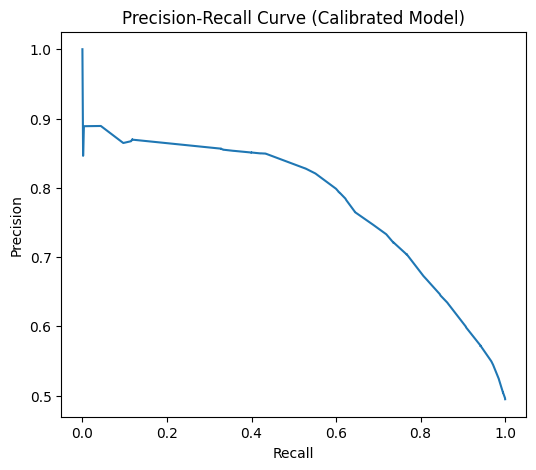

Calibrated PR-AUC: 0.7809865651163896


In [43]:
precision_vals, recall_vals, _ = precision_recall_curve(y_test, y_prob_cal)

plt.figure(figsize=(6,5))
plt.plot(recall_vals, precision_vals)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve (Calibrated Model)")
plt.show()

pr_auc_value = auc(recall_vals, precision_vals)
print("Calibrated PR-AUC:", pr_auc_value)

### Threshold Optimization

In [44]:
thresholds = np.arange(0.1, 0.9, 0.05)

best_recall = 0
best_threshold = 0

for t in thresholds:
    preds = (y_prob_cal >= t).astype(int)
    rec = recall_score(y_test, preds)

    if rec > best_recall:
        best_recall = rec
        best_threshold = t

print("Best Threshold:", best_threshold)
print("Best Recall:", best_recall)

Best Threshold: 0.1
Best Recall: 0.9945644189804613


###  Apply best threshold

In [45]:
y_pred_optimized = (y_prob_cal >= best_threshold).astype(int)

print("\nClassification Report (Optimized Threshold):")
print(classification_report(y_test, y_pred_optimized))


Classification Report (Optimized Threshold):
              precision    recall  f1-score   support

           0       0.90      0.05      0.09      6948
           1       0.51      0.99      0.67      6807

    accuracy                           0.52     13755
   macro avg       0.70      0.52      0.38     13755
weighted avg       0.70      0.52      0.38     13755



## Risk Stratification

In [46]:
def risk_category(prob):
    if prob < best_threshold:
        return "Low Risk"
    elif prob < 0.75:
        return "Moderate Risk"
    else:
        return "High Risk"

risk_levels = [risk_category(p) for p in y_prob_cal]

### 95% Confidence Interval of Risk Prediction

In [47]:
# Bootstrap for one patient (first patient in X_test_tree)
boot_preds = []

# Get the first test sample for which we want a CI
test_sample_for_ci = X_test_tree.iloc[[0]]

for _ in range(100):
    # Sample indices from the training set with replacement
    sample_indices = np.random.choice(len(X_train_tree), size=len(X_train_tree), replace=True)

    # Use .iloc for both X_train_tree and y_train_res to select rows
    X_boot = X_train_tree.iloc[sample_indices]
    y_boot = y_train_res.iloc[sample_indices]

    model_boot = XGBClassifier(**best_xgb.get_params())
    model_boot.set_params(use_label_encoder=False, eval_metric='logloss')
    model_boot.fit(X_boot, y_boot)

    # Predict for the single test sample
    boot_preds.append(model_boot.predict_proba(test_sample_for_ci)[0][1])

ci_lower = np.percentile(boot_preds, 2.5)
ci_upper = np.percentile(boot_preds, 97.5)

print("95% Confidence Interval:", (ci_lower, ci_upper))

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [14:58:36] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [14:58:36] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [14:58:37] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [14:58:37] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:

95% Confidence Interval: (np.float32(0.466408), np.float32(0.584816))


### SHAP Explainability (Global + Individual)

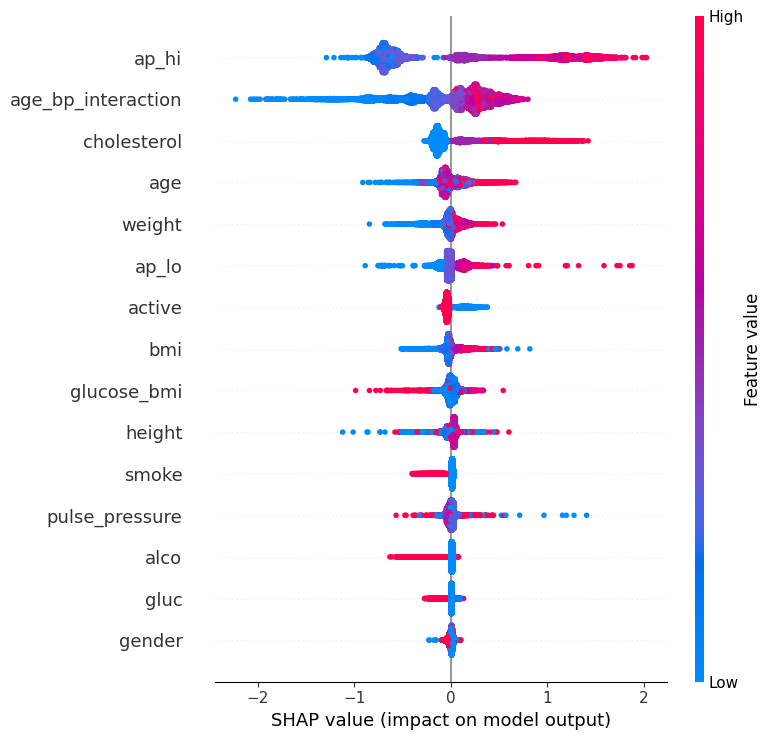

In [48]:
explainer = shap.TreeExplainer(calibrated_model.estimator)
shap_values = explainer.shap_values(X_test_tree)

shap.summary_plot(shap_values, X_test_tree, feature_names=X.columns)

shap.force_plot(
    explainer.expected_value,
    shap_values[0],
    X_test_tree.iloc[0],
    feature_names=X.columns
)

# Save Final Model

In [49]:
joblib.dump(calibrated_model, "cardioshield_final_model.pkl")
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']